# 34. Truncated sequential rollout fine-tuning, uniform large-angle faults (three sensors)

**Starting point:** the pooled calibration Transformer and KAIST splits from notebook 33. **Sequential training pattern:** notebook 06's detached calibration-state rollout. Each example is a contiguous sequence of 5-second windows; the initial calibration is perturbed **once**, and the same estimate is passed forward after every correction. The model is trained against **post-update calibration state error**, not just independently sampled one-step targets.

- Single **uniform-magnitude** rotation sampler, `0–170°`, and uniform signed clock offsets, `±500 ms`. No Student-t or fine/coarse branch.
- One faulty sensor per sequence item. Fault types default to 25% rotation-only, 25% tau-only, 50% combined. Rotational directions are mostly isotropic, with 25% axis-aligned examples for isolated X/Y/Z recovery. Every magnitude still uses the same uniform bounds.
- One-step truncated backpropagation: backward after each physical window; detach carried calibration before the next one; **one optimizer step per sequence batch**. This is *on-policy state-distribution training with temporal truncation*, not exact full-horizon BPTT.
- Healthy sensors, all translations, and true physical calibration stay fixed through a sequence. This is an intentional controlled fault-recovery experiment; identifying which sensor is faulty is a separate task.
- Normalized Smooth L1 on post-update SO(3) and tau errors limits dominance of near-170° examples. No paired +/- training loss and no observability head.
- Separate deterministic validation/test rollouts, checkpoint snapshots, pre/post-source comparison, and signed-axis rollout diagnostics.

**Important:** A uniform rotation *magnitude* and uniform axis direction are not Haar-uniform on SO(3). Also, this experiment does **not** guarantee convergence in fundamentally uninformative windows.

## 1. Imports and repository root

In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the nn-obs-calib repository root containing src/obscalib.")

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, KAISTSequenceChunkDataset, build_kaist_sequence_specs, collate_kaist_sequence_chunks, make_kaist_dataloader
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber, apply_prior_perturbation
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.update import CalibrationUpdater
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch
from obscalib.geometry.lie import se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.pipeline.window_step import WindowStep
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint
from obscalib.training.metrics_logger import MetricsLogger
import gc

print("Repository root:", ROOT)
print("PyTorch:", torch.__version__)

from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from obscalib.geometry.lie import so3_exp

Repository root: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
PyTorch: 2.7.1+cu126


## 2. Experiment configuration

In [ ]:
RUN_NAME = "kaist_pooled_calibration_paired_002.18_truncated_uniform_rollout"
SOURCE_RUN_NAME = "kaist_pooled_calibration_paired_002.16_correction_only"  # Or 002.17 for an explicit ablation.
INITIAL_CHECKPOINT = ROOT / "runs" / SOURCE_RUN_NAME / "best.pt"
RESUME_TRAINING = False
RESUME_TRAINING_CHECKPOINT = ROOT / "runs" / RUN_NAME / "last.pt"

RANDOM_SEED = 12345
TRAIN_SEQUENCE_SEED = 23456
VALIDATION_SEQUENCE_SEED = 34567
TEST_SEQUENCE_SEED = 45678

DEVICE_NAME = "cuda"
DEVICE = torch.device("cuda" if DEVICE_NAME == "auto" and torch.cuda.is_available() else DEVICE_NAME)
MODEL_DTYPE = torch.float32
CALIBRATION_KEYS = ("imu", "lidar", "lidar_right")
WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700
NUM_WORKERS = 0

# Temporal truncation is ONE window. Gradients accumulate over SEQUENCE_LENGTH windows,
# then the optimizer takes ONE step. Use SEQUENCE_BATCH_SIZE=1 first on limited VRAM.
SEQUENCE_LENGTH = 8
TRAIN_SEQUENCE_STRIDE = SEQUENCE_LENGTH
VAL_SEQUENCE_STRIDE = SEQUENCE_LENGTH
TEST_SEQUENCE_STRIDE = SEQUENCE_LENGTH
SEQUENCE_BATCH_SIZE = 16
SEQUENCE_EVAL_BATCH_SIZE = 16

NUM_EPOCHS = 200
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0
LR_REDUCTION_FACTOR = 0.5
LR_PATIENCE_EPOCHS = 8
CHECKPOINT_EVERY_EPOCHS = 3
RUN_FULL_TRAINING = True
MAX_TRAIN_BATCHES = None  # None uses every training chunk; small integer for debugging only.
MAX_VAL_BATCHES = None

MEASUREMENT_DIM = 6
TOKEN_INPUT_DIM = MEASUREMENT_DIM + 2
D_MODEL = 128
N_HEADS = 8
NUM_TRANSFORMER_LAYERS = 12
DIM_FEEDFORWARD = 512
TRANSFORMER_DROPOUT = 0.0
NUM_SUMMARY_TOKENS = 1
POOLER_N_HEADS = 8
POOLER_DROPOUT = 0.0
MLP_HIDDEN_DIMS = (256, 128)
SHARED_FEATURE_DIM = 128
MLP_DROPOUT = 0.0
HEAD_HIDDEN_DIMS = (128, 64)
HEAD_DROPOUT = 0.0

ROTATION_LOSS_SCALE_RAD = np.deg2rad(5.0)
TIME_OFFSET_LOSS_SCALE_S = 0.050
ROTATION_LOSS_WEIGHT = 2.0
TIME_OFFSET_LOSS_WEIGHT = 1.0
ROTATION_MAX_RAD = np.deg2rad(170.0)
TIME_OFFSET_MAX_S = 0.500
# One magnitude distribution for all rotation and clock faults; fault-type mix is separate.
FAULT_TYPE_PROBABILITIES = {"rotation_only": 0.25, "tau_only": 0.25, "combined": 0.50}
AXIS_ALIGNED_ROTATION_PROBABILITY = 0.25  # Directional mix, NOT a second magnitude distribution.
ROTATION_UPDATE_GAIN = 1.0
TAU_UPDATE_GAIN = 1.0
MAX_ROTATION_STEP_DEG = None  # E.g. 45.0 for a controller ablation; default raw learned update.
MAX_TAU_STEP_MS = None
CONVERGENCE_ROTATION_DEG = 5.0
CONVERGENCE_TAU_MS = 15.0

# Keep the same KAIST reference calibration throughout a sequence. Applying independent
# true-calibration augmentation at every step would create fictitious repeated faults.
ENABLE_FRAME_RANDOMIZATION = False
ENABLE_TRUE_CALIBRATION_AUGMENTATION = False
ENABLE_MEASUREMENT_NOISE = False
ENABLE_SAMPLING_RATE_AUGMENTATION = False

if not INITIAL_CHECKPOINT.is_file() and not RESUME_TRAINING:
    raise FileNotFoundError(f"Cannot initialize model from {INITIAL_CHECKPOINT}")
assert set(FAULT_TYPE_PROBABILITIES) == {"rotation_only", "tau_only", "combined"}
assert np.isclose(sum(FAULT_TYPE_PROBABILITIES.values()), 1.0)
assert 0 < ROTATION_MAX_RAD < np.pi
assert SEQUENCE_LENGTH > 1 and SEQUENCE_BATCH_SIZE > 0

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
print("Run:", RUN_NAME, "| model initialization:", INITIAL_CHECKPOINT)
print("Uniform rotation magnitude: 0-170 deg; time offset: +/-500 ms")
print("Fault types:", FAULT_TYPE_PROBABILITIES)
print("Gradient horizon: one physical window; rollout steps:", SEQUENCE_LENGTH)

Run: kaist_pooled_calibration_002.18_truncated_uniform_rollout | model initialization: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.16_correction_only/best.pt
Uniform rotation magnitude: 0-170 deg; time offset: +/-500 ms
Fault types: {'rotation_only': 0.25, 'tau_only': 0.25, 'combined': 0.5}
Gradient horizon: one physical window; rollout steps: 8


## 3. KAIST rig and train/validation/test split (unchanged from notebook 33)

In [46]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")

TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES

if len(ALL_SEQUENCE_NAMES) != len(set(ALL_SEQUENCE_NAMES)):
    raise ValueError("Train, validation, and test sequence sets overlap.")

T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [0.486485, -0.711672, 0.506809, 0.397052],
    [-0.706447, 0.0208933, 0.707457, 1.90953],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

# Right LiDAR -> body, in the same convention as T_B_L for the left LiDAR.
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109,  1.91294],
    [ 0.0,       0.0,       0.0,       1.0],
], dtype=float)

T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 1.7],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)

print("train:", TRAIN_NAMES)
print("validation:", VAL_NAMES)
print("test:", TEST_NAMES)

train: ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16']
validation: ['Urban26', 'Urban28']
test: ['Urban38', 'Urban39']


In [27]:
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")

# The 3-sensor experiment must never silently fall back to 2 sensors.
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Missing required right-LiDAR pose CSV for {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

train_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TRAIN_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
val_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in VAL_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
test_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TEST_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

for split_name, dataset in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(dataset.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"{split_name} dataset has calibration keys {dataset.calibration_keys}, expected {CALIBRATION_KEYS}")

print(train_dataset.summary())
print()
print(val_dataset.summary())
print()
print(test_dataset.summary())

KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704

KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658

KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 15.4 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiD

## 4. Chronological chunk loaders (adapted from notebook 06)

In [47]:
sequence_train_dataset = KAISTSequenceChunkDataset(train_dataset, sequence_length=SEQUENCE_LENGTH, sequence_stride=TRAIN_SEQUENCE_STRIDE)
sequence_val_dataset = KAISTSequenceChunkDataset(val_dataset, sequence_length=SEQUENCE_LENGTH, sequence_stride=VAL_SEQUENCE_STRIDE)
sequence_test_dataset = KAISTSequenceChunkDataset(test_dataset, sequence_length=SEQUENCE_LENGTH, sequence_stride=TEST_SEQUENCE_STRIDE)

sequence_train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED)
sequence_train_loader = DataLoader(sequence_train_dataset, batch_size=SEQUENCE_BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, collate_fn=collate_kaist_sequence_chunks, generator=sequence_train_shuffle_generator)
sequence_val_loader = DataLoader(sequence_val_dataset, batch_size=SEQUENCE_EVAL_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, collate_fn=collate_kaist_sequence_chunks)
sequence_test_loader = DataLoader(sequence_test_dataset, batch_size=SEQUENCE_EVAL_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, collate_fn=collate_kaist_sequence_chunks)

for label, dataset, loader in (("train", sequence_train_dataset, sequence_train_loader), ("val", sequence_val_dataset, sequence_val_loader), ("test", sequence_test_dataset, sequence_test_loader)):
    print(f"{label}: {len(dataset)} sequence chunks, {len(loader)} sequence batches")

first_chunk_batch = collate_kaist_sequence_chunks([sequence_train_dataset[0]])
assert isinstance(first_chunk_batch, (tuple, list)) and len(first_chunk_batch) == SEQUENCE_LENGTH
assert all(tuple(step.current_calibration) == CALIBRATION_KEYS for step in first_chunk_batch)
print("Chronological sequence collator: PASS | steps:", len(first_chunk_batch))
del first_chunk_batch

train: 248 sequence chunks, 16 sequence batches
val: 51 sequence chunks, 4 sequence batches
test: 86 sequence chunks, 6 sequence batches
Chronological sequence collator: PASS | steps: 8


## 5. Same pretrained pooled Transformer and calibration head as notebook 33

In [48]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=TOKEN_INPUT_DIM, d_model=D_MODEL, n_heads=N_HEADS, num_layers=NUM_TRANSFORMER_LAYERS, dim_feedforward=DIM_FEEDFORWARD, dropout=TRANSFORMER_DROPOUT, num_summary_tokens=NUM_SUMMARY_TOKENS, activation="gelu"),
    mlp=MLPConfig(hidden_dims=MLP_HIDDEN_DIMS, output_dim=SHARED_FEATURE_DIM, activation="gelu", dropout=MLP_DROPOUT),
    pooler=CalibrationPoolerConfig(
        n_heads=POOLER_N_HEADS,
        dropout=POOLER_DROPOUT,
        calibration_context_dim=0,           # CALIBRATION_CONTEXT_DIM
    ),

    head=PooledCalibrationHeadConfig(
        calibration_context_dim=0,
        hidden_dims=HEAD_HIDDEN_DIMS,
        activation="gelu",
        dropout=HEAD_DROPOUT,
    ),
)

geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=CALIBRATION_KEYS)
model = PooledCalibrationModel(model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
calibration_updater = CalibrationUpdater()
window_step = WindowStep(geometry_processor=geometry_processor, tokenizer=tokenizer, model=model, calibration_updater=calibration_updater)

# if not getattr(model, "uses_calibration_context", False):
#     raise RuntimeError("This experiment requires the pooled model to use numeric calibration context.")

print(model)
print()
print("Parameters:", sum(parameter.numel() for parameter in model.parameters()))
print("Trainable parameters:", sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad))
print("Pooler calibration context dim:", model.pooler.calibration_context_dim)
print("Head calibration context dim:", model.head.config.calibration_context_dim)

PooledCalibrationModel(
  (transformer_encoder): SummaryTokenTransformerEncoder(
    (input_projection): Linear(in_features=8, out_features=128, bias=True)
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-11): 12 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
          )
          (linear1): Linear(in_features=128, out_features=512, bias=True)
          (dropout): Dropout(p=0.0, inplace=False)
          (linear2): Linear(in_features=512, out_features=128, bias=True)
          (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (dropout1): Dropout(p=0.0, inplace=False)
          (dropout2): Dropout(p=0.0, inplace=False)
        )
      )
    )
  )
  (pooler): CalibrationPooler(
    (attention): MultiheadAttention(
      (out_proj): NonDynamicallyQ

## 6. One uniform prior distribution, one faulty sensor per sequence

In [49]:
uniform_prior_config = PriorPerturbationConfig(
    enabled=True,
    probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=ROTATION_MAX_RAD, distribution=PerturbationDistribution.UNIFORM),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(maximum=TIME_OFFSET_MAX_S, distribution=PerturbationDistribution.UNIFORM),
    one_calibration_per_sample=True,
    one_rotation_axis_per_sample=False,
    one_perturbation_type_per_sample=False,
)
uniform_prior_perturber = CalibrationPriorPerturber(uniform_prior_config)

def make_augmentation_generator(seed: int):
    return torch.Generator(device=DEVICE.type).manual_seed(seed)

def detach_calibration(states):
    return {key: CalibrationState(transform=state.transform.detach(), time_offset=state.time_offset.detach()) for key, state in states.items()}

def copy_calibration(states):
    return {key: CalibrationState(transform=state.transform.clone(), time_offset=state.time_offset.clone()) for key, state in states.items()}

def sample_rollout_initial_calibration(truth, generator):
    """Draw a uniform rotation/tau fault ONCE; select exactly one faulty sensor per item."""
    _, sample_xi, sample_tau = uniform_prior_perturber(truth, generator=generator)
    first_state = next(iter(truth.values()))
    B = first_state.transform.shape[0]
    device, dtype = first_state.transform.device, first_state.transform.dtype

    selected = {key: ((sample_xi[key][:, :3].norm(dim=-1) > 1e-9) | (sample_tau[key][:, 0].abs() > 1e-9)) for key in CALIBRATION_KEYS}
    assert torch.stack(tuple(selected.values()), dim=-1).sum(dim=-1).eq(1).all(), "The sampler must select exactly one sensor per sequence item."

    weights = torch.tensor([FAULT_TYPE_PROBABILITIES[name] for name in ("rotation_only", "tau_only", "combined")], dtype=dtype, device=device)
    modes = torch.multinomial(weights, B, replacement=True, generator=generator)
    axis_aligned = torch.rand(B, device=device, generator=generator) < AXIS_ALIGNED_ROTATION_PROBABILITY
    chosen_axis = torch.randint(0, 3, (B,), device=device, generator=generator)
    axis_sign = 2 * torch.randint(0, 2, (B,), device=device, generator=generator) - 1
    direction = F.one_hot(chosen_axis, num_classes=3).to(dtype=dtype) * axis_sign.to(dtype)[:, None]
    states = {}
    for key in CALIBRATION_KEYS:
        source_rotation = sample_xi[key][:, :3]
        axis_rotation = source_rotation.norm(dim=-1, keepdim=True) * direction
        dr = torch.where(axis_aligned[:, None], axis_rotation, source_rotation) * (modes != 1).to(dtype)[:, None]  # Drop rotation for tau-only.
        dt = sample_tau[key] * (modes != 0).to(dtype)[:, None]         # Drop tau for rotation-only.
        T = truth[key].transform.clone()
        T[:, :3, :3] = so3_exp(dr) @ T[:, :3, :3]
        # Preserve the original translation. Left-multiplying an SE(3) transform
        # would rotate its origin, although the rho head has never been trained.
        states[key] = CalibrationState(transform=T, time_offset=truth[key].time_offset + dt)

    return states, selected, modes

print(uniform_prior_config)

PriorPerturbationConfig(enabled=True, probability=1.0, probability_by_key={}, rotation=PerturbationMagnitudeConfig(maximum=2.9670597283903604, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), translation=None, time_offset=PerturbationMagnitudeConfig(maximum=0.5, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False)


### Verify sensor selection, bounds, and initial-state semantics

In [50]:
def verify_uniform_rollout_sampler():
    base = window_batch_to(collate_windows([train_dataset[int(i)] for i in np.linspace(0, len(train_dataset)-1, 8, dtype=int)]), DEVICE, dtype=MODEL_DTYPE)
    truth = base.current_calibration
    prior, selected, modes = sample_rollout_initial_calibration(truth, make_augmentation_generator(TRAIN_SEQUENCE_SEED+100))
    for key in CALIBRATION_KEYS:
        expected_t = truth[key].transform[:, :3, 3]
        torch.testing.assert_close(prior[key].transform[:, :3, 3], expected_t)
        Rdelta = prior[key].transform[:, :3, :3] @ truth[key].transform[:, :3, :3].transpose(-1, -2)
        # Relative rotation cannot exceed 170 degrees; trace/acos is only a diagnostic.
        angle = torch.rad2deg(torch.acos(((Rdelta.diagonal(dim1=-2,dim2=-1).sum(-1)-1)/2).clamp(-1,1)))
        assert (angle <= np.rad2deg(ROTATION_MAX_RAD) + .1).all()
        assert ((prior[key].time_offset-truth[key].time_offset).abs() <= TIME_OFFSET_MAX_S+1e-6).all()
        assert (angle[~selected[key]] < .2).all()
        torch.testing.assert_close(prior[key].time_offset[~selected[key]], truth[key].time_offset[~selected[key]])
    print("Sampler invariants: PASS | modes", {name: int((modes==j).sum()) for j,name in enumerate(FAULT_TYPE_PROBABILITIES)})
    del base

verify_uniform_rollout_sampler()

Sampler invariants: PASS | modes {'rotation_only': 2, 'tau_only': 0, 'combined': 6}


### Empirical single-uniform sampler coverage

Sampled fault modes: {'rotation_only': '25.3%', 'tau_only': '24.2%', 'combined': '50.4%'}
Fraction with rotation > 130 deg: 0.18359375


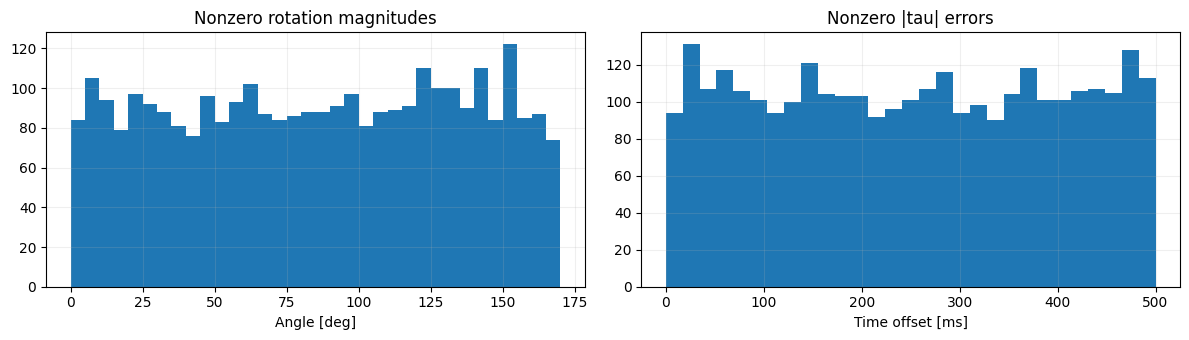

In [51]:
SAMPLER_CHECK_B = 4096
prototype = window_batch_to(collate_windows([train_dataset[0]]), DEVICE, dtype=MODEL_DTYPE).current_calibration
replicated_truth = {key: CalibrationState(transform=state.transform.repeat(SAMPLER_CHECK_B,1,1), time_offset=state.time_offset.repeat(SAMPLER_CHECK_B,1)) for key,state in prototype.items()}
replicated_prior, replicated_masks, sampled_modes = sample_rollout_initial_calibration(replicated_truth, make_augmentation_generator(TRAIN_SEQUENCE_SEED+120))
sampled_angles, sampled_taus = [], []
for key in CALIBRATION_KEYS:
    mask = replicated_masks[key]
    R = replicated_prior[key].transform[:, :3, :3] @ replicated_truth[key].transform[:, :3, :3].transpose(-1,-2)
    theta = torch.rad2deg(torch.acos(((R.diagonal(dim1=-2,dim2=-1).sum(-1)-1)/2).clamp(-1,1)))
    sampled_angles.append(theta[mask].cpu().numpy())
    sampled_taus.append((1000*(replicated_prior[key].time_offset - replicated_truth[key].time_offset).abs()[:,0])[mask].cpu().numpy())
all_angles = np.concatenate(sampled_angles)
all_taus = np.concatenate(sampled_taus)
print("Sampled fault modes:", {name: f"{100*(sampled_modes==i).float().mean():.1f}%" for i,name in enumerate(FAULT_TYPE_PROBABILITIES)})
print("Fraction with rotation > 130 deg:", (all_angles > 130).mean())
assert (all_angles <= 170.1).all() and (all_taus <= 500.01).all()
assert (all_angles > 130).mean() > 0.04, "Uniform large-angle tail unexpectedly sparse"
fig, axes = plt.subplots(1,2,figsize=(12,3.5))
axes[0].hist(all_angles[all_angles>0.1], bins=np.linspace(0,170,35))
axes[1].hist(all_taus[all_taus>0.01], bins=np.linspace(0,500,30))
axes[0].set(title="Nonzero rotation magnitudes", xlabel="Angle [deg]")
axes[1].set(title="Nonzero |tau| errors", xlabel="Time offset [ms]")
for ax in axes: ax.grid(alpha=.2)
fig.tight_layout(); plt.show()
del replicated_prior, replicated_truth, replicated_masks, prototype, sampled_angles, sampled_taus

## 7. Differentiable sensor-isolated correction update

In [52]:
from obscalib.calibration.context import calibration_state_to_context


def rollout_forward(window, states):
    """Use the SAME GeometryProcessor -> Tokenizer -> pooled model as notebook 33."""
    canonical = geometry_processor(window.streams, window.metadata, states)
    tokens = tokenizer(canonical, observability=None)
    if tokens.x.shape[-1] != TOKEN_INPUT_DIM or tuple(tokens.calibration_keys) != CALIBRATION_KEYS:
        raise ValueError("Rollout tokens have wrong dimension or calibration routing.")
    calibration_context = {key: calibration_state_to_context(states[key]) for key in CALIBRATION_KEYS}
    return model(tokens, calibration_context)


def apply_rollout_correction(states, output, selected):
    """Only selected faulty sensor may change R/tau. Preserve all translations."""
    updated = {}
    for key in CALIBRATION_KEYS:
        state, prediction = states[key], output.predictions[key]
        active = selected[key].to(device=state.transform.device)
        dphi = ROTATION_UPDATE_GAIN * prediction.delta_xi[:, :3]
        if MAX_ROTATION_STEP_DEG is not None:
            maximum = np.deg2rad(MAX_ROTATION_STEP_DEG)
            dphi = dphi * (maximum / dphi.norm(dim=-1, keepdim=True).clamp_min(1e-12)).clamp(max=1.0)
        dtau = TAU_UPDATE_GAIN * prediction.delta_tau
        if MAX_TAU_STEP_MS is not None:
            dtau = dtau.clamp(-MAX_TAU_STEP_MS/1000.0, MAX_TAU_STEP_MS/1000.0)

        T_updated = state.transform.clone()
        R_updated = so3_exp(dphi) @ state.transform[:, :3, :3]
        T_updated[:, :3, :3] = torch.where(active[:, None, None], R_updated, state.transform[:, :3, :3])
        tau_updated = torch.where(active[:, None], state.time_offset + dtau, state.time_offset)
        updated[key] = CalibrationState(transform=T_updated, time_offset=tau_updated)
    return updated


def assert_sequence_truth_consistent(step, truth, tol=1e-5):
    """Per-sequence ground-truth extrinsics/clocks must remain fixed."""
    for key in CALIBRATION_KEYS:
        if not torch.allclose(step.current_calibration[key].transform, truth[key].transform, atol=tol, rtol=0):
            raise RuntimeError(f"True {key} calibration changed within a sequence chunk.")
        if not torch.allclose(step.current_calibration[key].time_offset, truth[key].time_offset, atol=tol, rtol=0):
            raise RuntimeError(f"True {key} clock changed within a sequence chunk.")


def rollout_state_loss(truth, updated, selected):
    """Post-update, active-sensor SO(3) and tau errors; robust component-wise normalized Huber."""
    first = next(iter(truth.values()))
    B = first.transform.shape[0]
    per_item = torch.zeros(B, dtype=first.transform.dtype, device=first.transform.device)
    rotation_per_item = torch.zeros_like(per_item)
    tau_per_item = torch.zeros_like(per_item)

    for key in CALIBRATION_KEYS:
        R_error = truth[key].transform[:, :3, :3] @ updated[key].transform[:, :3, :3].transpose(-1, -2)
        T_error = torch.eye(4, device=R_error.device, dtype=R_error.dtype).repeat(B, 1, 1)
        T_error[:, :3, :3] = R_error
        error_phi = se3_log(T_error)[:, :3]
        error_tau = truth[key].time_offset - updated[key].time_offset
        rot_loss = F.smooth_l1_loss(error_phi / ROTATION_LOSS_SCALE_RAD, torch.zeros_like(error_phi), reduction="none").mean(dim=-1)
        tau_loss = F.smooth_l1_loss(error_tau / TIME_OFFSET_LOSS_SCALE_S, torch.zeros_like(error_tau), reduction="none").mean(dim=-1)
        mask = selected[key].to(dtype=rot_loss.dtype)
        per_item = per_item + mask * (ROTATION_LOSS_WEIGHT*rot_loss + TIME_OFFSET_LOSS_WEIGHT*tau_loss)
        rotation_per_item = rotation_per_item + mask*torch.rad2deg(torch.linalg.vector_norm(error_phi, dim=-1))
        tau_per_item = tau_per_item + mask*(1000.0*error_tau[:, 0].abs())
    return per_item.mean(), rotation_per_item.detach(), tau_per_item.detach()


def initial_state_errors(truth, prior, selected):
    _, angle, tau = rollout_state_loss(truth, prior, selected)
    return angle, tau

## 8. Training objective, truncation and epoch runner

In [53]:
def sequence_step_weights(length, device):
    # Favor later residual states while still supervising the approach trajectory.
    weights = torch.arange(1, length+1, device=device, dtype=MODEL_DTYPE)
    return weights / weights.sum()


# WARNING: Detachment is across each physical window, not inside the 12-layer Transformer.
# Call backward immediately after each window. The next window receives detached
# corrected calibration. No graph from earlier Transformers survives beyond this step.
def run_rollout_epoch(loader, *, training, generator, global_step=0, max_batches=None, label="rollout"):
    model.train(training)
    sums = {k: 0.0 for k in ("loss_total", "final_rotation_deg", "final_tau_ms", "initial_rotation_deg", "initial_tau_ms", "final_converged", "final_rotation_improvement", "final_tau_improvement")}
    total_sequences = 0
    mode_names = ("rotation_only", "tau_only", "combined")
    mode_sums = {name: {"count":0, "final_rotation_deg":0.0, "final_tau_ms":0.0, "final_converged":0.0} for name in mode_names}
    angle_bins = (0.0, 5.0, 30.0, 60.0, 90.0, 130.0, 170.1)
    angle_bin_sums = {f"{lo:g}-{hi:g}": {"count":0, "final_rotation_deg":0.0, "improve_fraction":0.0} for lo,hi in zip(angle_bins[:-1],angle_bins[1:])}
    start_time = time.perf_counter()
    effective_batches = min(len(loader), max_batches) if max_batches is not None else len(loader)

    for batch_number, sequence_batches in enumerate(loader):
        if max_batches is not None and batch_number >= max_batches:
            break
        assert len(sequence_batches) == SEQUENCE_LENGTH
        first = window_batch_to(sequence_batches[0], DEVICE, dtype=MODEL_DTYPE)
        truth = detach_calibration(first.current_calibration)
        states, selected, modes = sample_rollout_initial_calibration(truth, generator)
        init_rot, init_tau = initial_state_errors(truth, states, selected)
        B = init_rot.numel()
        weights = sequence_step_weights(len(sequence_batches), DEVICE)
        if training:
            optimizer.zero_grad(set_to_none=True)

        sequence_loss_value = 0.0
        last_rot, last_tau = None, None
        for t, cpu_step in enumerate(sequence_batches):
            step = first if t == 0 else window_batch_to(cpu_step, DEVICE, dtype=MODEL_DTYPE)
            assert_sequence_truth_consistent(step, truth)
            with torch.set_grad_enabled(training):
                output = rollout_forward(step, states)
                corrected = apply_rollout_correction(states, output, selected)
                loss, last_rot, last_tau = rollout_state_loss(truth, corrected, selected)
                weighted = weights[t] * loss
                if not torch.isfinite(weighted):
                    raise RuntimeError(f"Nonfinite post-update loss at step {t}; check near-pi rotations and sensor timestamps.")
                if training:
                    weighted.backward()  # ONE Transformer graph at a time.
            sequence_loss_value += float(weighted.detach())
            states = detach_calibration(corrected)
            del output, corrected, weighted, loss

        if training:
            if GRADIENT_CLIP_NORM is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
            optimizer.step()  # A SINGLE update after aggregating all K windows.
            global_step += 1

        sums["loss_total"] += sequence_loss_value * B
        sums["initial_rotation_deg"] += init_rot.sum().item()
        sums["initial_tau_ms"] += init_tau.sum().item()
        sums["final_rotation_deg"] += last_rot.sum().item()
        sums["final_tau_ms"] += last_tau.sum().item()
        sums["final_rotation_improvement"] += (init_rot-last_rot).sum().item()
        sums["final_tau_improvement"] += (init_tau-last_tau).sum().item()
        sums["final_converged"] += ((last_rot < CONVERGENCE_ROTATION_DEG) & (last_tau < CONVERGENCE_TAU_MS)).sum().item()
        total_sequences += B
        for j,name in enumerate(mode_names):
            mask = modes == j
            n = int(mask.sum())
            if n:
                entry = mode_sums[name]
                entry["count"] += n
                entry["final_rotation_deg"] += float(last_rot[mask].sum())
                entry["final_tau_ms"] += float(last_tau[mask].sum())
                entry["final_converged"] += int(((last_rot[mask] < CONVERGENCE_ROTATION_DEG) & (last_tau[mask] < CONVERGENCE_TAU_MS)).sum())
        rotation_active = modes != 1
        for lo,hi in zip(angle_bins[:-1],angle_bins[1:]):
            mask = rotation_active & (init_rot >= lo) & (init_rot < hi)
            n = int(mask.sum())
            if n:
                item = angle_bin_sums[f"{lo:g}-{hi:g}"]
                item["count"] += n
                item["final_rotation_deg"] += float(last_rot[mask].sum())
                item["improve_fraction"] += float(((init_rot[mask] - last_rot[mask]) / init_rot[mask].clamp_min(1e-6)).sum())

        # if training and (batch_number + 1) % 25 == 0:
        #     print(f"{label} {batch_number+1}/{effective_batches} | loss={sequence_loss_value:.4f} | last rot={last_rot.mean().item():.2f} deg tau={last_tau.mean().item():.1f} ms")

    if total_sequences == 0:
        raise ValueError("No rollout chunks were processed.")
    elapsed = time.perf_counter()-start_time
    metrics = {**{k:v/total_sequences for k,v in sums.items()}, "epoch_time_s":elapsed, "num_sequences":total_sequences}
    for name,values in mode_sums.items():
        count = max(1, values["count"])
        metrics[f"mode/{name}/count"] = values["count"]
        for key in ("final_rotation_deg", "final_tau_ms", "final_converged"):
            metrics[f"mode/{name}/{key}"] = values[key] / count
    for name,values in angle_bin_sums.items():
        count = max(1, values["count"])
        metrics[f"angle/{name}/count"] = values["count"]
        metrics[f"angle/{name}/final_rotation_deg"] = values["final_rotation_deg"] / count if values["count"] else float("nan")
        metrics[f"angle/{name}/improve_fraction"] = values["improve_fraction"] / count if values["count"] else float("nan")
    return metrics, global_step

## 9. Optimizer, learning-rate scheduler and complete checkpoint snapshot

In [54]:
RUN_DIR = ROOT / "runs" / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT_PATH = RUN_DIR / "best.pt"
LAST_CHECKPOINT_PATH = RUN_DIR / "last.pt"
METRICS_PATH = RUN_DIR / "metrics.jsonl"

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=LR_REDUCTION_FACTOR, patience=LR_PATIENCE_EPOCHS)

EXPERIMENT_SNAPSHOT = {
    "run_name": RUN_NAME,
    "architecture": "PooledCalibrationModel",
    "model_config": model_config,
    "windowing_config": windowing_config,
    "rig_calibration": rig_calibration,
    "measurement_dim": MEASUREMENT_DIM,
    "calibration_keys": CALIBRATION_KEYS,
    "sequence_split": {"train": tuple(TRAIN_NAMES), "validation": tuple(VAL_NAMES), "test": tuple(TEST_NAMES)},
    "initialization_checkpoint": str(INITIAL_CHECKPOINT),
    "training_strategy": "detached_one_window_BPTT_with_multi_window_rollout",
    "sequence_length": SEQUENCE_LENGTH,
    "gradient_horizon_windows": 1,
    "train_sequence_stride": TRAIN_SEQUENCE_STRIDE,
    "val_sequence_stride": VAL_SEQUENCE_STRIDE,
    "train_sequence_batch_size": SEQUENCE_BATCH_SIZE,
    "uniform_prior_config": uniform_prior_config,
    "fault_type_probabilities": FAULT_TYPE_PROBABILITIES,
    "axis_aligned_rotation_probability": AXIS_ALIGNED_ROTATION_PROBABILITY,
    "loss_type": "smooth_l1_post_update_state",
    "rotation_loss_scale_rad": ROTATION_LOSS_SCALE_RAD,
    "time_offset_loss_scale_s": TIME_OFFSET_LOSS_SCALE_S,
    "rotation_loss_weight": ROTATION_LOSS_WEIGHT,
    "time_offset_loss_weight": TIME_OFFSET_LOSS_WEIGHT,
    "checkpoint_selection_metric": "val/loss_total",
    "selected_sensor_update_only": True,
    "translation_update_enabled": False,
    "true_calibration_augmentation": False,
    "frame_randomization": False,
    "observability_input": False,
    "seeds": {"random": RANDOM_SEED, "train_sequence": TRAIN_SEQUENCE_SEED, "validation_sequence": VALIDATION_SEQUENCE_SEED, "test_sequence": TEST_SEQUENCE_SEED},
}

start_epoch, global_step, best_validation_loss = 0, 0, float("inf")
train_rollout_generator = make_augmentation_generator(TRAIN_SEQUENCE_SEED)
if RESUME_TRAINING:
    checkpoint = load_training_checkpoint(RESUME_TRAINING_CHECKPOINT, model=model, optimizer=optimizer, scheduler=scheduler, generators={"train_sequence":train_rollout_generator,"train_shuffle":sequence_train_shuffle_generator}, map_location=DEVICE, restore_rng_state=True)
    start_epoch = int(checkpoint.get("epoch", 0))
    global_step = int(checkpoint.get("global_step", 0))
    best_validation_loss = float((checkpoint.get("extra_state") or {}).get("best_validation_loss", float("inf")))
    print("Restored optimizer/scheduler/model at epoch", start_epoch)
else:
    load_training_checkpoint(INITIAL_CHECKPOINT, model=model, map_location=DEVICE, restore_rng_state=False)
    print("Initialized model weights only from:", INITIAL_CHECKPOINT)

Initialized model weights only from: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.16_correction_only/best.pt


## 10. Smoke test: gradient, physical state update, and detached carry

In [55]:
RUN_GRADIENT_SMOKE_TEST = not RESUME_TRAINING
if RUN_GRADIENT_SMOKE_TEST:
    seq = collate_kaist_sequence_chunks([sequence_train_dataset[0]])
    sample = window_batch_to(seq[0], DEVICE, dtype=MODEL_DTYPE)
    reference = detach_calibration(sample.current_calibration)
    prior, masks, modes = sample_rollout_initial_calibration(reference, make_augmentation_generator(TRAIN_SEQUENCE_SEED + 11))
    model.train()
    optimizer.zero_grad(set_to_none=True)
    output = rollout_forward(sample, prior)
    updated = apply_rollout_correction(prior, output, masks)
    smoke_loss, _, _ = rollout_state_loss(reference, updated, masks)
    smoke_loss.backward()
    gradients = [p.grad for p in model.parameters() if p.grad is not None]
    grad_norm = torch.stack([g.detach().square().sum() for g in gradients]).sum().sqrt().item()
    assert np.isfinite(smoke_loss.item()) and np.isfinite(grad_norm) and grad_norm > 0
    for key in CALIBRATION_KEYS:
        healthy = ~masks[key]
        torch.testing.assert_close(updated[key].transform[healthy], reference[key].transform[healthy])
        torch.testing.assert_close(updated[key].time_offset[healthy], reference[key].time_offset[healthy])
        torch.testing.assert_close(updated[key].transform[:, :3, 3], reference[key].transform[:, :3, 3])
    detached = detach_calibration(updated)
    assert all(not state.transform.requires_grad and not state.time_offset.requires_grad for state in detached.values())
    print(f"ROLLOUT GRADIENT AND STATE ISOLATION: PASS | loss={smoke_loss.item():.4f} | grad_norm={grad_norm:.4g}")
    optimizer.zero_grad(set_to_none=True)
    del seq, sample, reference, prior, masks, modes, output, updated, smoke_loss, detached, gradients
    gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()

ROLLOUT GRADIENT AND STATE ISOLATION: PASS | loss=0.4390 | grad_norm=47.38


### Complete sequence smoke test (one batch, no parameter update)

In [56]:
RUN_SEQUENCE_SMOKE_TEST = not RESUME_TRAINING
if RUN_SEQUENCE_SMOKE_TEST:
    metrics, _ = run_rollout_epoch(sequence_train_loader, training=False, generator=make_augmentation_generator(TRAIN_SEQUENCE_SEED+300), max_batches=1, label="Sequence smoke")
    for key in ("loss_total", "initial_rotation_deg", "final_rotation_deg", "initial_tau_ms", "final_tau_ms"):
        assert np.isfinite(metrics[key]), f"Nonfinite full-sequence diagnostic: {key}"
    print("FULL SEQUENCE ROLLOUT: PASS |", {key: round(metrics[key],3) for key in ("loss_total", "final_rotation_deg", "final_tau_ms")})

FULL SEQUENCE ROLLOUT: PASS | {'loss_total': 11.58, 'final_rotation_deg': 80.768, 'final_tau_ms': 9.637}


## 11. Fixed-seed pretraining rollout baseline (before fine-tuning)

In [57]:
RUN_INITIAL_BASELINE = True
initial_validation_metrics = None
if RUN_INITIAL_BASELINE and not RESUME_TRAINING:
    initial_validation_metrics, _ = run_rollout_epoch(sequence_val_loader, training=False, generator=make_augmentation_generator(VALIDATION_SEQUENCE_SEED), max_batches=MAX_VAL_BATCHES, label="Source validation")
    print("Initial checkpoint validation:", {k:round(v,3) for k,v in initial_validation_metrics.items() if k not in ("epoch_time_s",)})

Initial checkpoint validation: {'loss_total': 4.783, 'final_rotation_deg': 30.964, 'final_tau_ms': 14.658, 'initial_rotation_deg': 60.763, 'initial_tau_ms': 186.405, 'final_converged': 0.51, 'final_rotation_improvement': 29.799, 'final_tau_improvement': 171.747, 'num_sequences': 51, 'mode/rotation_only/count': 16, 'mode/rotation_only/final_rotation_deg': 39.496, 'mode/rotation_only/final_tau_ms': 10.991, 'mode/rotation_only/final_converged': 0.438, 'mode/tau_only/count': 15, 'mode/tau_only/final_rotation_deg': 3.629, 'mode/tau_only/final_tau_ms': 7.53, 'mode/tau_only/final_converged': 0.733, 'mode/combined/count': 20, 'mode/combined/final_rotation_deg': 44.641, 'mode/combined/final_tau_ms': 22.938, 'mode/combined/final_converged': 0.4, 'angle/0-5/count': 0, 'angle/0-5/final_rotation_deg': nan, 'angle/0-5/improve_fraction': nan, 'angle/5-30/count': 4, 'angle/5-30/final_rotation_deg': 3.449, 'angle/5-30/improve_fraction': 0.607, 'angle/30-60/count': 7, 'angle/30-60/final_rotation_deg': 6

## 12. Full sequential fine-tuning (one update after each sequence batch)

In [58]:
torch.cuda.empty_cache()

In [59]:
history = []
if RUN_FULL_TRAINING:
    with MetricsLogger(METRICS_PATH, append=RESUME_TRAINING) as logger:
        if not RESUME_TRAINING:
            logger.log_config(model_config, name="model_config")
            logger.log_config(uniform_prior_config, name="uniform_prior_config")
            logger.log_config({"run_name":RUN_NAME, "initialization":str(INITIAL_CHECKPOINT), "sequence_length":SEQUENCE_LENGTH, "training_strategy":"one_window_truncated_rollout", "learning_rate":LEARNING_RATE, "fault_types":FAULT_TYPE_PROBABILITIES}, name="experiment")

        for epoch in range(start_epoch+1, NUM_EPOCHS+1):
            print("\n" + "="*92 + f"\nEpoch {epoch}/{NUM_EPOCHS}")
            train_metrics, global_step = run_rollout_epoch(sequence_train_loader, training=True, generator=train_rollout_generator, global_step=global_step, max_batches=MAX_TRAIN_BATCHES, label="Train rollout")
            val_metrics, _ = run_rollout_epoch(sequence_val_loader, training=False, generator=make_augmentation_generator(VALIDATION_SEQUENCE_SEED), global_step=global_step, max_batches=MAX_VAL_BATCHES, label="Validation rollout")
            scheduler.step(val_metrics["loss_total"])
            lr = optimizer.param_groups[0]["lr"]
            history.append({"epoch": epoch, "lr":lr, **{f"train/{k}":v for k,v in train_metrics.items()}, **{f"val/{k}":v for k,v in val_metrics.items()}})
            logger.log_metrics({**train_metrics,"lr":lr}, split="train_rollout", epoch=epoch, step=global_step)
            logger.log_metrics(val_metrics, split="validation_rollout", epoch=epoch, step=global_step)

            saved = []
            if val_metrics["loss_total"] < best_validation_loss:
                best_validation_loss = val_metrics["loss_total"]
                save_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, optimizer=optimizer, scheduler=scheduler, epoch=epoch, global_step=global_step, metrics=val_metrics, generators={"train_sequence":train_rollout_generator,"train_shuffle":sequence_train_shuffle_generator}, extra_state={"best_validation_loss":best_validation_loss,"experiment":EXPERIMENT_SNAPSHOT})
                saved.append("best")
            if epoch % CHECKPOINT_EVERY_EPOCHS == 0 or epoch == NUM_EPOCHS:
                save_training_checkpoint(LAST_CHECKPOINT_PATH, model=model, optimizer=optimizer, scheduler=scheduler, epoch=epoch, global_step=global_step, metrics=val_metrics, generators={"train_sequence":train_rollout_generator,"train_shuffle":sequence_train_shuffle_generator}, extra_state={"best_validation_loss":best_validation_loss,"experiment":EXPERIMENT_SNAPSHOT})
                saved.append("last")
            print(f"train={train_metrics['loss_total']:.4f} | val={val_metrics['loss_total']:.4f} | initial rot={val_metrics['initial_rotation_deg']:.1f} 
                deg -> final rot={val_metrics['final_rotation_deg']:.1f} deg | final tau={val_metrics['final_tau_ms']:.1f} ms | 
                converged={100*val_metrics['final_converged']:.1f}% | lr={lr:.2e} | saved={','.join(saved) or '-'}")
            gc.collect()
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
                torch.cuda.empty_cache()
else:
    print("Full training disabled. Run only the source-model diagnostic and inference sections.")


Epoch 1/200
train=9.2539 | val=7.4892 | initial rot=60.8 deg -> final rot=39.6 deg | final tau=115.7 ms | converged=0.0% | lr=1.00e-03 | saved=best

Epoch 2/200
train=5.4092 | val=5.5388 | initial rot=60.8 deg -> final rot=33.9 deg | final tau=51.4 ms | converged=5.9% | lr=1.00e-03 | saved=best

Epoch 3/200
train=6.0854 | val=5.4714 | initial rot=60.8 deg -> final rot=36.4 deg | final tau=30.0 ms | converged=11.8% | lr=1.00e-03 | saved=best,last

Epoch 4/200
train=5.5687 | val=5.1305 | initial rot=60.8 deg -> final rot=33.3 deg | final tau=29.3 ms | converged=9.8% | lr=1.00e-03 | saved=best

Epoch 5/200
train=4.9247 | val=5.4381 | initial rot=60.8 deg -> final rot=38.2 deg | final tau=23.9 ms | converged=11.8% | lr=1.00e-03 | saved=-

Epoch 6/200
train=5.7962 | val=5.8489 | initial rot=60.8 deg -> final rot=44.1 deg | final tau=17.1 ms | converged=19.6% | lr=1.00e-03 | saved=last

Epoch 7/200
train=6.0804 | val=5.4151 | initial rot=60.8 deg -> final rot=37.3 deg | final tau=19.3 ms | 

KeyboardInterrupt: 

## 13. Training curves and checkpoint verification

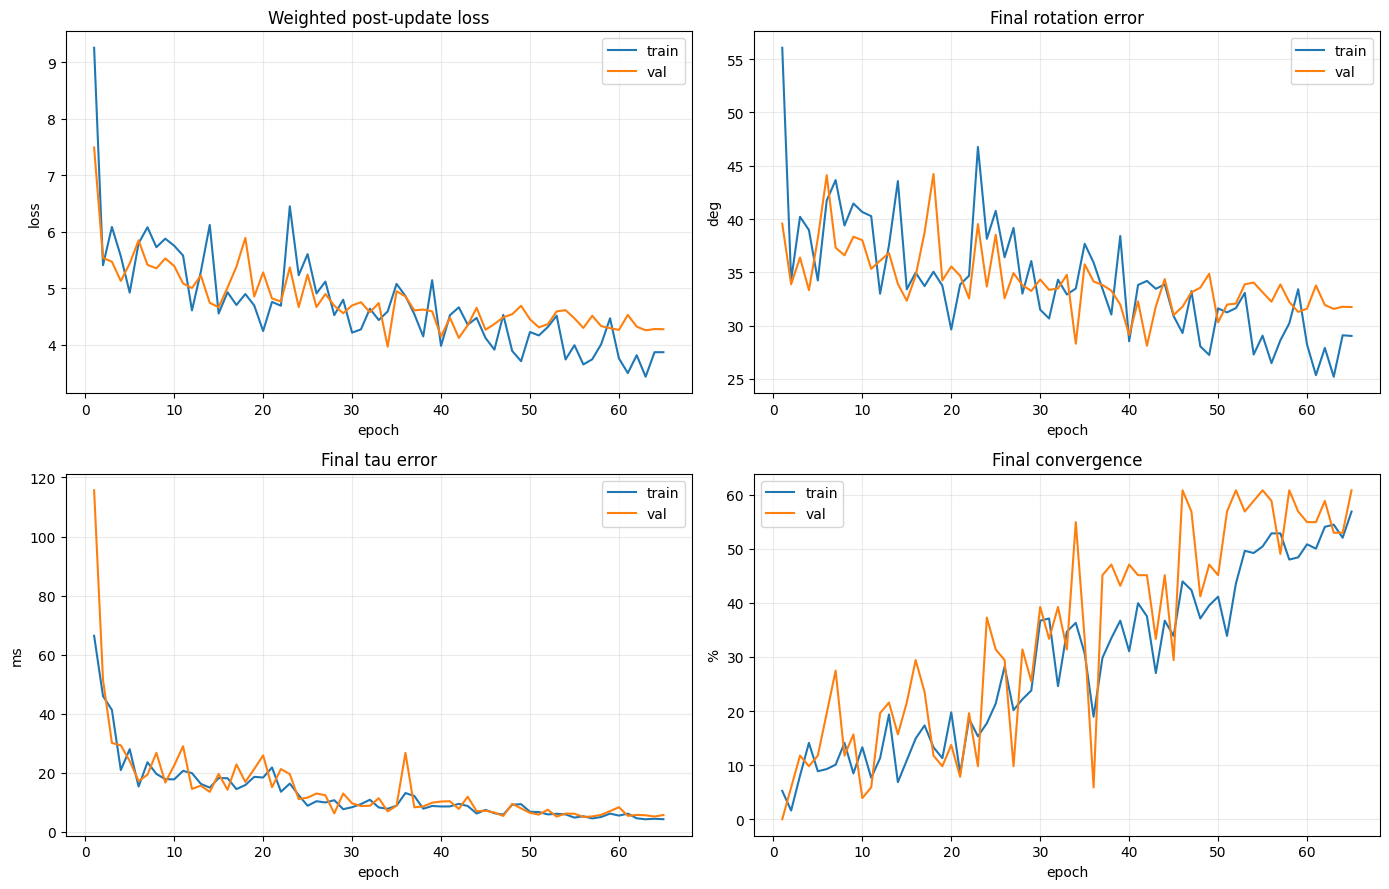

Verified: best.pt epoch 34
Verified: last.pt epoch 63


In [60]:
if history:
    epochs = [h["epoch"] for h in history]
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    for split in ("train", "val"):
        axes[0,0].plot(epochs, [h[f"{split}/loss_total"] for h in history], label=split)
        axes[0,1].plot(epochs, [h[f"{split}/final_rotation_deg"] for h in history], label=split)
        axes[1,0].plot(epochs, [h[f"{split}/final_tau_ms"] for h in history], label=split)
        axes[1,1].plot(epochs, [100*h[f"{split}/final_converged"] for h in history], label=split)
    for ax, name, unit in zip(axes.ravel(), ("Weighted post-update loss", "Final rotation error", "Final tau error", "Final convergence"), ("loss", "deg", "ms", "%")):
        ax.set_title(name); ax.set_ylabel(unit); ax.set_xlabel("epoch"); ax.grid(alpha=.25); ax.legend()
    fig.tight_layout(); plt.show()

from obscalib.training.checkpoint import read_training_checkpoint
for path in (BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH):
    if path.is_file():
        payload = read_training_checkpoint(path, map_location="cpu")
        snapshot = (payload.get("extra_state") or {}).get("experiment")
        assert isinstance(snapshot, dict) and snapshot["run_name"] == RUN_NAME
        assert isinstance(snapshot["model_config"], PooledCalibrationModelConfig)
        assert snapshot["gradient_horizon_windows"] == 1
        print("Verified:", path.name, "epoch", payload.get("epoch"))
        del payload

## 14. Identically seeded held-out evaluation of source and fine-tuned checkpoints

In [61]:
def evaluate_checkpoint_rollout(checkpoint_path, loader, seed, *, label):
    load_training_checkpoint(checkpoint_path, model=model, map_location=DEVICE, restore_rng_state=False)
    metrics, _ = run_rollout_epoch(loader, training=False, generator=make_augmentation_generator(seed), label=label)
    return metrics

if BEST_CHECKPOINT_PATH.is_file():
    source_test_metrics = evaluate_checkpoint_rollout(INITIAL_CHECKPOINT, sequence_test_loader, TEST_SEQUENCE_SEED, label="Source test")
    trained_test_metrics = evaluate_checkpoint_rollout(BEST_CHECKPOINT_PATH, sequence_test_loader, TEST_SEQUENCE_SEED, label="Fine-tuned test")
    print(f"{'metric':30s} {'source':>12s} {'trained':>12s}")
    for key in ("loss_total", "initial_rotation_deg", "final_rotation_deg", "initial_tau_ms", "final_tau_ms", "final_converged", "final_rotation_improvement", "final_tau_improvement"):
        print(f"{key:30s} {source_test_metrics[key]:12.4f} {trained_test_metrics[key]:12.4f}")
    print("\nConvergence by fault type:")
    for fault_type in ("rotation_only", "tau_only", "combined"):
        stem = f"mode/{fault_type}/"
        print(f"{fault_type:14s}: source {100*source_test_metrics[stem+'final_converged']:.1f}%, trained {100*trained_test_metrics[stem+'final_converged']:.1f}%")
    print("\nRotation error by initial-angle band:")
    for band in ("0-5", "5-30", "30-60", "60-90", "90-130", "130-170.1"):
        key = f"angle/{band}/final_rotation_deg"
        print(f"{band:9s}: N={trained_test_metrics[f'angle/{band}/count']:.0f}, source={source_test_metrics[key]:.2f} deg, trained={trained_test_metrics[key]:.2f} deg")
    load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
else:
    print("No fine-tuned checkpoint. Run full training or set RUN_FULL_TRAINING=True.")

metric                               source      trained
loss_total                           6.7970       5.8283
initial_rotation_deg                62.9780      62.9780
final_rotation_deg                  48.5962      43.4459
initial_tau_ms                     185.9091     185.9091
final_tau_ms                         8.6388       6.5911
final_converged                      0.5116       0.4419
final_rotation_improvement          14.3818      19.5321
final_tau_improvement              177.2703     179.3180

Convergence by fault type:
rotation_only : source 38.1%, trained 19.0%
tau_only      : source 73.3%, trained 86.7%
combined      : source 40.0%, trained 22.9%

Rotation error by initial-angle band:
0-5      : N=0, source=nan deg, trained=nan deg
5-30     : N=6, source=2.92 deg, trained=3.84 deg
30-60    : N=9, source=2.23 deg, trained=24.15 deg
60-90    : N=5, source=14.00 deg, trained=31.02 deg
90-130   : N=22, source=80.38 deg, trained=73.31 deg
130-170.1: N=14, source=159.99 deg

## 15. Signed-axis rollout trajectories: source versus trained checkpoint

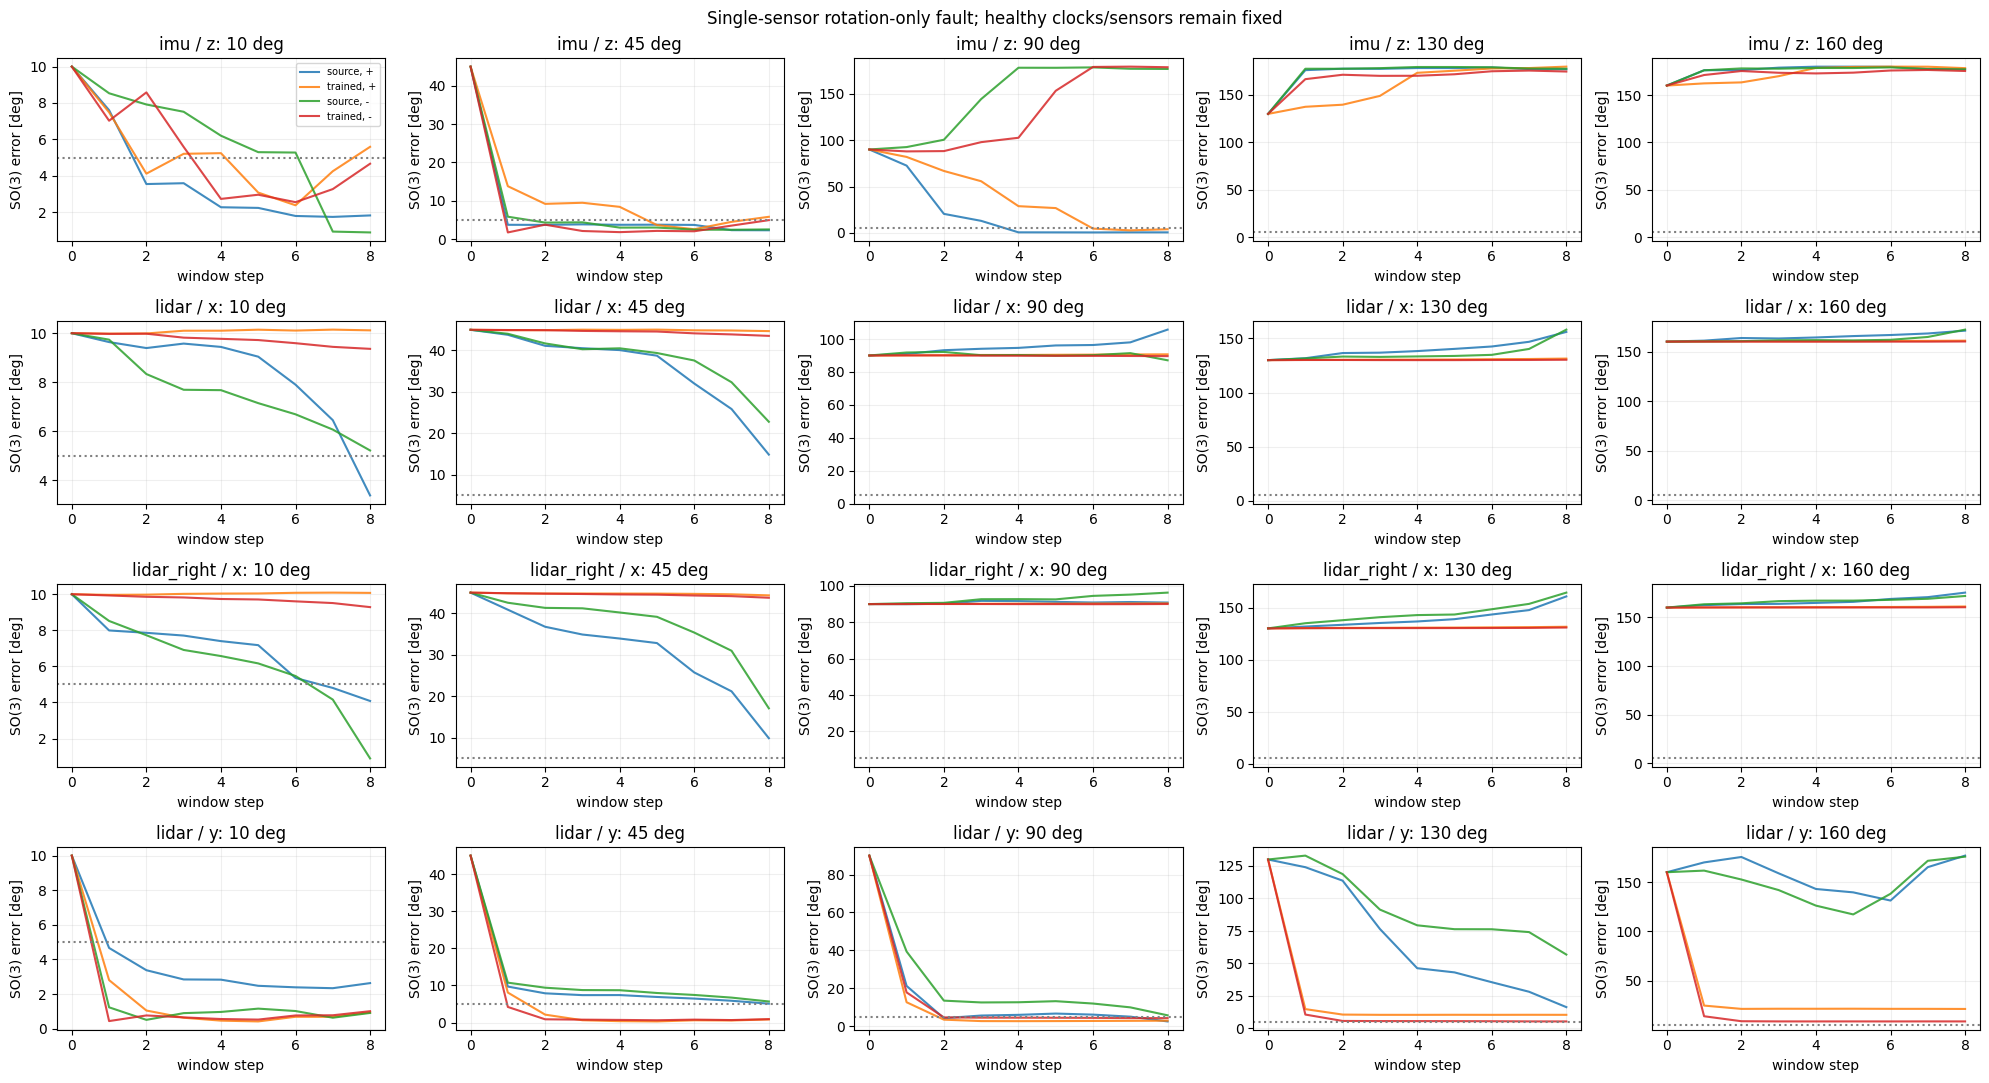

In [62]:
# Keep this diagnostic much smaller than exhaustive 3 x 3 x many-angle testing.
DIAGNOSTIC_SENSOR_AXES = (("imu", 2), ("lidar", 0), ("lidar_right", 0), ("lidar", 1))
DIAGNOSTIC_INITIAL_ANGLES = (10.0, 45.0, 90.0, 130.0, 160.0)
DIAGNOSTIC_SIGNS = (1.0, -1.0)
DIAGNOSTIC_TEST_CHUNK_INDEX = 0

@torch.inference_mode()
def trace_fixed_axis_case(sequence_batches, sensor, axis, signed_degrees):
    first = window_batch_to(sequence_batches[0], DEVICE, dtype=MODEL_DTYPE)
    truth = detach_calibration(first.current_calibration)
    B = truth[sensor].transform.shape[0]
    if B != 1: raise ValueError("Trace one physical sequence at a time.")
    states = copy_calibration(truth)
    dr = torch.zeros((B,3), dtype=MODEL_DTYPE, device=DEVICE)
    dr[:,axis] = np.deg2rad(signed_degrees)
    states[sensor].transform[:, :3, :3] = so3_exp(dr) @ truth[sensor].transform[:, :3, :3]
    selected = {k: torch.full((B,), k==sensor, dtype=torch.bool, device=DEVICE) for k in CALIBRATION_KEYS}
    initial_rot, _ = initial_state_errors(truth, states, selected)
    errors = [float(initial_rot[0])]
    for t, cpu_step in enumerate(sequence_batches):
        step = first if t==0 else window_batch_to(cpu_step, DEVICE, dtype=MODEL_DTYPE)
        output = rollout_forward(step, states)
        states = detach_calibration(apply_rollout_correction(states, output, selected))
        _, rot, _ = rollout_state_loss(truth, states, selected)
        errors.append(float(rot[0]))
    return errors

if BEST_CHECKPOINT_PATH.is_file():
    singleton_sequence = collate_kaist_sequence_chunks([sequence_test_dataset[DIAGNOSTIC_TEST_CHUNK_INDEX]])
    traces = {}
    for label, path in (("source", INITIAL_CHECKPOINT), ("trained", BEST_CHECKPOINT_PATH)):
        load_training_checkpoint(path, model=model, map_location=DEVICE, restore_rng_state=False)
        model.eval()
        for sensor, axis in DIAGNOSTIC_SENSOR_AXES:
            for angle in DIAGNOSTIC_INITIAL_ANGLES:
                for sign in DIAGNOSTIC_SIGNS:
                    case = (sensor, axis, float(sign*angle))
                    traces[(label, *case)] = trace_fixed_axis_case(singleton_sequence, *case)
    load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)

    fig, axes = plt.subplots(len(DIAGNOSTIC_SENSOR_AXES), len(DIAGNOSTIC_INITIAL_ANGLES), figsize=(20, 11), squeeze=False)
    for i, (sensor, axis) in enumerate(DIAGNOSTIC_SENSOR_AXES):
        for j, angle in enumerate(DIAGNOSTIC_INITIAL_ANGLES):
            ax = axes[i,j]
            for sign in DIAGNOSTIC_SIGNS:
                for label in ("source", "trained"):
                    curve = traces[(label, sensor, axis, sign*angle)]
                    ax.plot(range(len(curve)), curve, label=f"{label}, {'+' if sign>0 else '-'}", alpha=.85)
            ax.axhline(CONVERGENCE_ROTATION_DEG, color="gray", linestyle=":")
            ax.set_title(f"{sensor} / {'xyz'[axis]}: {angle:g} deg")
            ax.set_xlabel("window step"); ax.set_ylabel("SO(3) error [deg]"); ax.grid(alpha=.2)
            if i==0 and j==0: ax.legend(fontsize=7)
    fig.suptitle("Single-sensor rotation-only fault; healthy clocks/sensors remain fixed")
    fig.tight_layout(); plt.show()
else:
    print("Training checkpoint missing; signed-axis comparisons skipped.")

In [63]:
torch.cuda.empty_cache()

## 16. Interpretation

**Promote this checkpoint only if** validation/test rollout losses and final convergence improve against its source checkpoint, *and* the small-angle signed-axis plots do not regress. Uniform large-angle training may improve recovery for observable axes without identifying weakly observable directions.

If the model plateaus, first inspect (1) nonzero updates near the true calibration, (2) sign of the local correction Jacobian, (3) training fault-type proportions and observed magnitude histogram, (4) the mismatch between fixed 8-window rollouts and longer deployment rollouts. Avoid changing the architecture or declaring a capacity limit solely from aggregate rollout MSE.

**Memory note:** each Transformer graph is freed after its own backward pass; PyTorch still retains parameter gradients and optimizer state for the full sequence batch. If VRAM is tight, reduce `SEQUENCE_BATCH_SIZE` before reducing `SEQUENCE_LENGTH`.